# Modelo propuesto: ensamble con regresión por diferencias de pares por estación

**Curso:** Machine Learning · **Profesor:** Lihki Rubio Ortega
**Grupo:** Yuryen Rollo, Betzaida Ruiz

En el capítulo anterior los siete modelos de regresión quedaron muy cerca unos de otros: en 2025 el RMSE va de
`0.7227` (Random Forest) a `0.7607 m/s` (árbol de decisión), y Random Forest y XGBoost no se distinguen
estadísticamente. Los residuos de todos conservan la misma estructura, lo que indica que el límite lo pone la
información disponible más que la flexibilidad del algoritmo. En este capítulo proponemos un modelo que usa esa
información de otra manera: en lugar de aprender el viento de mañana directamente, aprende **cuánto se aparta una
hora de otras horas conocidas de la misma estación**. Es la regresión por diferencias de pares (PADRE, *Pairwise
Difference Regression*; Tynes et al., 2021), que adaptamos al problema formando los pares dentro de cada estación.
El modelo final promedia dos versiones de PADRE con los tres mejores modelos del capítulo anterior.

**Reproducibilidad.** El modelo está en `e3/padre.py` (clase `PadreEstacion`) y los experimentos en `scripts/`.
Este notebook solo lee sus resultados y combina predicciones guardadas. Desde la carpeta del repositorio:

```
python scripts/padre_anidado.py            # PADRE + XGBoost con validación anidada (≈ 1 h 30 min)
python scripts/padre_anidado.py --final    # su evaluación única en 2025
python scripts/ensamble_padre.py           # ensamble de 5: 2024 y evaluación única en 2025 (≈ 25 min)
python scripts/ensamble_semillas.py        # el ensamble con otras 4 semillas (≈ 1 h)
python scripts/padre_solo.py               # variante sin modelos del curso (regla previa)
python scripts/merf_anidado.py             # Random Forest de efectos mixtos (regla previa, ≈ 1 h)
python scripts/rotacion_anidado.py         # Rotation Forest (regla previa, ≈ 1 h)
```

Usamos el mismo conjunto de modelado, la misma partición y la misma semilla (`42`) que en el capítulo anterior.

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests

sys.path.insert(0, str(Path.cwd()))
from e3 import SEED
from e3 import evaluacion as ev
from e3.datos import RESULTADOS, cargar, pliegues_externos

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
CORRIDAS = RESULTADOS / "corridas"
ENS = RESULTADOS / "ensamble_padre"
ENSAMBLE = "Ensamble PADRE (5)"
COMPONENTES = ["Random Forest", "XGBoost", "SVR", "PADRE-XGB", "PADRE-RF"]

TR, TE, F = cargar()
y_te = TE.y.to_numpy()
EXT = pliegues_externos(TR)
tm = pd.read_csv(RESULTADOS / "tabla_maestra_resumen.csv")
OPT = dict(tm[tm.elegido].set_index("modelo").optimizador)   # optimizador elegido de cada modelo del curso


def archivo(modelo, optimizador, pliegue):
    return f"{modelo}__{optimizador}__{pliegue}".replace(" ", "_").replace("(", "").replace(")", "")


def predicciones(pliegues):
    """Pronósticos guardados de los 7 modelos del curso y de los dos PADRE, concatenados en los pliegues dados."""
    P = {}
    for n in pliegues:
        for m, o in OPT.items():
            P.setdefault(m, []).append(np.load(CORRIDAS / f"{archivo(m, o, n)}.npy").astype(float))
        for c in ["XGB", "RF"]:
            P.setdefault(f"PADRE-{c}", []).append(np.load(ENS / f"PADRE_{c}__{n}.npy").astype(float))
    P = {k: np.concatenate(v) for k, v in P.items()}
    P[ENSAMBLE] = np.mean([P[k] for k in COMPONENTES], 0)
    return P


va24 = np.concatenate([va for _, _, va in EXT])
y24, t24 = TR.y.to_numpy()[va24], TR.t.to_numpy()[va24]
P24 = predicciones([n for n, _, _ in EXT])
P25 = predicciones(["final"])
rmse = lambda y, p: float(np.sqrt(np.mean((y - p) ** 2)))
print(f"2024 (validación externa): {len(y24):,} filas | 2025 (prueba): {len(y_te):,} filas")
print(f"RMSE del ensamble: 2024 {rmse(y24, P24[ENSAMBLE]):.4f} | 2025 {rmse(y_te, P25[ENSAMBLE]):.4f}")

2024 (validación externa): 71,508 filas | 2025 (prueba): 213,972 filas
RMSE del ensamble: 2024 0.8216 | 2025 0.7193


## 6.1 La idea: aprender diferencias dentro de cada estación

**PADRE.** Un regresor común aprende `y ≈ f(x)`. PADRE entrena un regresor `g` sobre **pares** de filas
`(i, j)` para predecir la diferencia de sus objetivos a partir de la fila `i` y de la diferencia entre ambas:

$$g(x_i,\; x_i - x_j) \approx y_i - y_j .$$

Para pronosticar una fila nueva `x` de la estación `s` se toman `M` filas de entrenamiento de esa estación, las
**anclas** `j ∈ A_s`, cuyo objetivo `y_j` ya se conoce, y se promedia lo que cada una predice:

$$\hat y(x) = \frac{1}{M} \sum_{j \in A_s} \big[\, y_j + g(x,\; x - x_j) \,\big].$$

**Por qué formar los pares dentro de la estación.** Supongamos que el viento de mañana tiene una parte común a
todas las estaciones, una parte fija de cada sitio (altitud, rugosidad, exposición a la brisa) y ruido:
`y = f(x) + α_s + ε`. Para dos filas de la misma estación,

$$y_i - y_j = f(x_i) - f(x_j) + (\varepsilon_i - \varepsilon_j),$$

es decir, **el efecto del sitio `α_s` se cancela** y `g` solo tiene que aprender cómo cambia el viento cuando
cambian las condiciones. El nivel propio de la estación vuelve a entrar por las anclas: si `g` aprende bien la
diferencia, `y_j + g(x, x − x_j) ≈ f(x) + α_s + ε_j`, y al promediar

$$\hat y(x) \approx f(x) + \alpha_s + \frac{1}{M}\sum_{j \in A_s} \varepsilon_j .$$

El último término tiene media cero y su varianza baja con `M` (`σ²/M` si los ruidos de las anclas son
independientes). Así, el modelo obtiene el nivel de cada estación de sus propios datos, sin tener que deducirlo de
las coordenadas o de los rezagos, que es lo que hacen los modelos globales del capítulo anterior. Una estación con
menos de `500` filas de entrenamiento toma sus pares y anclas de la vecina geográfica más cercana con datos
suficientes: sin esta regla, una estación con `11` filas producía errores muy grandes en un trimestre.

**Configuración.** Cada fila de entrenamiento se empareja con `4` filas de su estación (el conjunto de pares tiene
cuatro veces más filas que el original) y cada pronóstico promedia `20` anclas. El regresor `g` es un XGBoost
(PADRE-XGB) o un Random Forest (PADRE-RF) con los hiperparámetros que eligió el bucle externo en el capítulo
anterior para cada pliegue. Estos valores se fijaron con los trimestres de 2024; la búsqueda con hasta `80` anclas
dio peor resultado en 2024 y no se llevó a 2025.

**Por qué promediar con los modelos del curso.** Si `f_1, …, f_K` son pronósticos y `f̄` su promedio, para cada
fila se cumple la descomposición de ambigüedad (Krogh y Vedelsby, 1995):

$$(y - \bar f)^2 = \frac{1}{K}\sum_{k=1}^{K} (y - f_k)^2 \;-\; \frac{1}{K}\sum_{k=1}^{K} (f_k - \bar f)^2 .$$

*Demostración.* Escribimos `y − f_k = (y − f̄) − (f_k − f̄)`. Al elevar al cuadrado y promediar sobre `k`, el
término cruzado es `−2 (y − f̄) · (1/K) Σ (f_k − f̄) = 0`, porque las desviaciones respecto de la media suman cero;
queda `(1/K) Σ (y − f_k)² = (y − f̄)² + (1/K) Σ (f_k − f̄)²`. ∎

El error del promedio es el error medio de los componentes **menos su desacuerdo**. Promediar modelos parecidos
casi no ayuda, porque el desacuerdo es pequeño. PADRE es útil como componente justamente porque se equivoca
distinto: sus errores dependen de las anclas de la estación y no solo de las predictoras. La sección 6.4 mide
los dos términos.

**El modelo propuesto** es el promedio simple, sin pesos ajustados, de cinco pronósticos: Random Forest, XGBoost y
SVR del capítulo anterior (los tres mejores en la validación de 2024) y PADRE-XGB y PADRE-RF. Al no tener pesos,
no hay nada que ajustar mirando los datos de prueba.

In [2]:
params = {m: json.loads((CORRIDAS / f"{archivo(m, OPT[m], 'final')}.json").read_text(encoding="utf-8"))["mejor_params"]
          for m in ["Random Forest", "XGBoost", "SVR"]}
pd.DataFrame([
    {"componente": "Random Forest", "origen": "capítulo anterior", "configuración (búsqueda final)": params["Random Forest"]},
    {"componente": "XGBoost", "origen": "capítulo anterior", "configuración (búsqueda final)": params["XGBoost"]},
    {"componente": "SVR", "origen": "capítulo anterior", "configuración (búsqueda final)": params["SVR"]},
    {"componente": "PADRE-XGB", "origen": "propuesto", "configuración (búsqueda final)": "4 pares, 20 anclas, motor = XGBoost anterior"},
    {"componente": "PADRE-RF", "origen": "propuesto", "configuración (búsqueda final)": "4 pares, 20 anclas, motor = Random Forest anterior"},
]).set_index("componente")

,origen,configuración (búsqueda final)
componente,,
Random Forest,capítulo anterior,"{'min_samples_leaf': 5, 'max_features': 0.23785127699240788, 'max_depth': 21, 'n_estimators': 232}"
XGBoost,capítulo anterior,"{'learning_rate': 0.011650335455725839, 'max_depth': 6, 'n_estimators': 993, 'min_child_weight': 60.72318357191729, ..."
SVR,capítulo anterior,"{'C': 9.999999999999993, 'kernel': 'rbf', 'gamma': 0.0010000000000000002, 'epsilon': 0.0}"
PADRE-XGB,propuesto,"4 pares, 20 anclas, motor = XGBoost anterior"
PADRE-RF,propuesto,"4 pares, 20 anclas, motor = Random Forest anterior"


## 6.2 Originalidad

PADRE se propuso en química computacional para predecir propiedades de moléculas con pocos datos. Buscamos su
uso en viento el 19 de octubre de 2026 con la cadena `("wind speed" OR "wind power" OR "wind forecast*") AND
("pairwise difference regression" OR "pairwise difference" OR "PADRE")`:

| Fuente | Resultados | Aplican PADRE a viento |
|---|---|---|
| Scopus (título, resumen y palabras clave) | `12` | `0`: seis son lugares llamados *Padre* (Padre Island, Padre Las Casas) y seis usan *pairwise differences* para comparar grupos (intervalos simultáneos, torres, simulaciones) |
| Web of Science (tema) | `65` | `0`: tres son lugares llamados *Padre*; los demás no contienen los términos en título, resumen ni palabras clave |
| Artículos que citan a Tynes et al. (2021), según Semantic Scholar | `≈ 58` | `0`: casi todos son de química, materiales y fármacos; los más cercanos tratan carga eléctrica y tráfico urbano |

Ningún trabajo aplica la regresión por diferencias de pares al pronóstico de viento, y la variante por estación,
con anclas del mismo sitio y respaldo en la vecina geográfica, es propia de este trabajo. Tampoco es un *import*:
ninguna biblioteca trae PADRE; el conjunto de pares, el sorteo de anclas y la regla de la vecina están
implementados en `e3/padre.py`.

## 6.3 Diseño de la evaluación

Usamos exactamente el protocolo del capítulo anterior:

- **Validación (2024).** Cada trimestre de 2024 se pronostica con modelos entrenados solo con lo anterior (ventana
  creciente desde 2020). Todas las decisiones se tomaron con estos cuatro trimestres.
- **Prueba (2025).** Se reentrena con 2020–2024 y se pronostica 2025 **una sola vez**, con todo ya decidido.
- **Comparación.** Pérdida cuadrática media por día; Diebold-Mariano con la corrección de Harvey, Leybourne y
  Newbold y ajuste de Holm por las siete comparaciones; Giacomini-White; Clark-West frente a Random Forest y
  XGBoost, porque el ensamble los contiene; SPA de Hansen y Model Confidence Set.

**Qué se fijó antes de mirar 2025.** El modelo propuesto (los cinco componentes, el promedio simple, `4` pares y
`20` anclas) y su variante base, PADRE + XGBoost con peso elegido en la validación interna (sección 6.7). Los
demás candidatos (sección 6.8) tuvieron una regla escrita en el código antes de correrlos: solo se evaluaban en
2025 si superaban a Random Forest en 2024 con `p < 0.05`. Ninguno la cumplió, así que 2025 se usó solo para los
dos modelos fijados.

## 6.4 Resultados en la validación de 2024

In [3]:
met24 = pd.DataFrame({k: ev.metricas(y24, P24[k]) for k in [ENSAMBLE, *OPT]}).T.sort_values("RMSE")
met24.round(4)

,RMSE,MAE,R2
Ensamble PADRE (5),0.8216,0.5832,0.6740
XGBoost,0.8315,0.5869,0.6661
Random Forest,0.8325,0.5861,0.6653
SVR,0.8354,0.5841,0.6630
Ridge,0.8461,0.5905,0.6543
Lasso,0.8461,0.5905,0.6542
KNN,0.8564,0.5877,0.6458
Árbol de decisión,0.8691,0.6096,0.6352


In [4]:
pr24 = pd.read_csv(ENS / "2024_pruebas.csv", index_col=0)
pr24[["dif. media pérdida", "IC 95 %", "DM-HLN", "p DM (Holm)", "p GW", "d de Cohen"]].round(5)

,dif. media pérdida,IC 95 %,DM-HLN,p DM (Holm),p GW,d de Cohen
rival,,,,,,
XGBoost,-0.02111,-0.0291 – -0.0127,-4.52195,0.00002,0.00003,-0.24555
Random Forest,-0.02916,-0.0396 – -0.0186,-6.55133,0.00000,0.00000,-0.38536
SVR,-0.03785,-0.0527 – -0.0196,-4.72761,0.00001,0.00000,-0.27230
Ridge,-0.06499,-0.0938 – -0.0322,-4.60900,0.00002,0.00000,-0.26915
Lasso,-0.06509,-0.0939 – -0.0323,-4.62079,0.00002,0.00000,-0.26990
KNN,-0.07746,-0.1021 – -0.0524,-7.43690,0.00000,0.00000,-0.45159
Árbol de decisión,-0.10797,-0.1283 – -0.0878,-13.11767,0.00000,0.00000,-0.78880


En los cuatro trimestres de 2024 el ensamble tiene el menor RMSE (`0.8216`, frente a `0.8315` de XGBoost y
`0.8325` de Random Forest) y su pérdida diaria es menor que la de cada uno de los siete modelos con diferencia
significativa después de Holm (frente a Random Forest, `DM = −6.55`). Este resultado se obtuvo antes de evaluar
2025 y es el que justificó llevar el ensamble a la prueba.

### ¿Por qué funciona? Los dos términos de la descomposición

,error medio de los componentes,desacuerdo,error del promedio,comprobación (medio − desacuerdo)
2024 · RF + XGB + SVR,0.69414,0.00929,0.68485,0.68485
2024 · ensamble (5),0.71141,0.03634,0.67507,0.67507
2025 · RF + XGB + SVR,0.52839,0.00701,0.52138,0.52138
2025 · ensamble (5),0.53992,0.02249,0.51743,0.51743


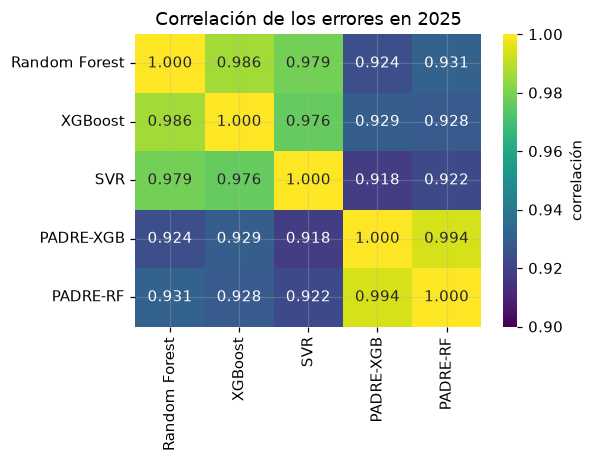

In [5]:
def ambiguedad(y, P, nombres):
    F_ = np.column_stack([P[k] for k in nombres])
    media = F_.mean(1)
    return {"error medio de los componentes": np.mean((y[:, None] - F_) ** 2),
            "desacuerdo": np.mean((F_ - media[:, None]) ** 2), "error del promedio": np.mean((y - media) ** 2)}


desc = pd.DataFrame({f"{per} · {nom}": ambiguedad(y, P, c) for per, y, P in [("2024", y24, P24), ("2025", y_te, P25)]
                     for nom, c in [("RF + XGB + SVR", COMPONENTES[:3]), ("ensamble (5)", COMPONENTES)]}).T
desc["comprobación (medio − desacuerdo)"] = desc["error medio de los componentes"] - desc["desacuerdo"]
display(desc.round(5))
err = pd.DataFrame({k: y_te - P25[k] for k in COMPONENTES})
fig, ax = plt.subplots(figsize=(5.5, 4.3))
sns.heatmap(err.corr(), annot=True, fmt=".3f", cmap="viridis", vmin=.9, vmax=1, ax=ax, cbar_kws={"label": "correlación"})
ax.set_title("Correlación de los errores en 2025")
plt.tight_layout()
plt.show()

La tabla verifica la descomposición con los datos: el error del promedio coincide exactamente con el error medio
de los componentes menos su desacuerdo. En 2025, el promedio de los tres modelos del curso parte de un error medio
de `0.5284` y un desacuerdo de solo `0.0070`: los tres se equivocan casi igual (sus errores tienen correlaciones
entre `0.976` y `0.986`), así que promediarlos apenas ayuda. Al agregar los dos PADRE, el error medio **sube** a
`0.5399`, porque cada PADRE por separado es peor que Random Forest (`RMSE` de `0.747` y `0.746`), pero el
desacuerdo **se triplica** (`0.0225`) y el error del promedio baja de `0.5214` a `0.5174`. En 2024 ocurre lo mismo
(desacuerdo de `0.0093` a `0.0363`). La correlación de los errores de PADRE con los de los modelos del curso es de
`0.92`–`0.93`, claramente menor: PADRE aporta una forma distinta de equivocarse. Los dos PADRE, en cambio, se
parecen mucho entre sí (`0.994`), porque comparten los pares y las anclas.

## 6.5 Resultados en la prueba de 2025 (evaluación única)

In [6]:
met25 = pd.read_csv(ENS / "2025_metricas.csv", index_col=0)
pers = TE.vel_l0.to_numpy()
met25["Mejora vs. persistencia"] = [ev.metricas(y_te, P25[k], pers)["Mejora vs. persistencia"] for k in met25.index]
met25.round(4)

,RMSE,MAE,R2,reducción RMSE del ensamble (%),Mejora vs. persistencia
Ensamble PADRE (5),0.7193,0.5102,0.7466,0.0000,0.1485
Random Forest,0.7227,0.5110,0.7442,0.4690,0.1445
XGBoost,0.7268,0.5123,0.7413,1.0332,0.1396
SVR,0.7311,0.5179,0.7382,1.6155,0.1345
Lasso,0.7330,0.5194,0.7369,1.8706,0.1323
Ridge,0.7330,0.5194,0.7369,1.8708,0.1323
KNN,0.7349,0.5134,0.7355,2.1166,0.1301
Árbol de decisión,0.7607,0.5370,0.7166,5.4377,0.0996


In [7]:
# IC 95 % del RMSE: bootstrap estacionario sobre días completos (bloques de 7 días)
ev.ic_rmse(TE.t, y_te, {k: P25[k] for k in [ENSAMBLE, "Random Forest", "XGBoost", "SVR"]}).round(4)

,RMSE,IC 95 % inf,IC 95 % sup
Ensamble PADRE (5),0.7193,0.6895,0.7484
Random Forest,0.7227,0.6919,0.7529
XGBoost,0.7268,0.6948,0.7579
SVR,0.7311,0.7008,0.7612


In [8]:
pr25 = pd.read_csv(ENS / "2025_pruebas.csv", index_col=0)
pr25[["dif. media pérdida", "IC 95 %", "DM-HLN", "p DM", "p DM (Holm)", "p GW", "δ de Cliff", "d de Cohen"]].round(5)

,dif. media pérdida,IC 95 %,DM-HLN,p DM,p DM (Holm),p GW,δ de Cliff,d de Cohen
rival,,,,,,,,
XGBoost,-0.01243,-0.0194 – -0.0069,-5.02380,0.00000,0.00000,0.00000,-0.02702,-0.32760
Random Forest,-0.00740,-0.0129 – -0.0030,-3.07794,0.00227,0.00227,0.00521,-0.01395,-0.18407
SVR,-0.01601,-0.0209 – -0.0105,-5.72006,0.00000,0.00000,0.00000,-0.05663,-0.35330
Ridge,-0.02033,-0.0297 – -0.0110,-4.68401,0.00000,0.00001,0.00000,-0.05410,-0.31068
Lasso,-0.02033,-0.0297 – -0.0110,-4.68407,0.00000,0.00001,0.00000,-0.05398,-0.31068
KNN,-0.02639,-0.0348 – -0.0193,-6.79426,0.00000,0.00000,0.00000,-0.06116,-0.41561
Árbol de decisión,-0.06847,-0.0839 – -0.0567,-14.27279,0.00000,0.00000,0.00000,-0.19105,-0.99661


In [9]:
cw = pd.read_csv(ENS / "2025_clark_west.csv", index_col=0)
spa = pd.read_csv(ENS / "2025_spa.csv", index_col=0)
mcs = pd.read_csv(ENS / "2025_mcs.csv", index_col=0)
display(cw.rename_axis("Clark-West: modelo restringido").round(4))
display(spa.rename_axis("SPA: referencia").round(4))
mcs.round(4)

,CW,p_valor
Clark-West: modelo restringido,,
Random Forest,9.6328,0.0
XGBoost,11.0225,0.0


,p_SPA (Hansen),p_SPA inferior,p_Reality Check (White)
SPA: referencia,,,
Random Forest,0.0105,0.0060,0.1955
XGBoost,0.0380,0.0015,0.0445
Ensamble PADRE (5),0.5270,0.5270,1.0000


,p_MCS,en el conjunto,pérdida media
Model name,,,
Ensamble PADRE (5),1.0000,True,0.5622
Random Forest,0.0060,False,0.5696
XGBoost,0.0005,False,0.5746
SVR,0.0000,False,0.5782
Ridge,0.0005,False,0.5825
Lasso,0.0005,False,0.5825
KNN,0.0000,False,0.5886
Árbol de decisión,0.0000,False,0.6307


En 2025 el ensamble es el modelo con menor error: `RMSE = 0.7193`, `MAE = 0.5102` y `R² = 0.747`, frente a
`0.7227` de Random Forest, el mejor modelo del curso. La mejora es pequeña en magnitud (`0.47 %` del RMSE frente a
Random Forest y `1.0 %` frente a XGBoost, el modelo que eligió la validación del capítulo anterior), pero
**consistente día a día**:

- **Diebold-Mariano con Holm:** el ensamble tiene menor pérdida que **cada uno de los siete modelos**, con
  diferencia significativa. Frente a Random Forest, `DM = −3.08` y `p = 0.0023`; el intervalo del 95 % de la
  diferencia diaria de pérdidas (`−0.0129` a `−0.0030`) no incluye el cero. Giacomini-White coincide en las siete
  comparaciones.
- **Clark-West:** como el ensamble contiene a Random Forest y a XGBoost, la comparación adecuada para modelos
  anidados es Clark-West. Rechaza la igualdad frente a ambos (`CW = 9.6` y `11.0`, `p ≈ 0`).
- **SPA y Reality Check:** con Random Forest como referencia, el SPA de Hansen rechaza que ningún otro modelo lo
  supere (`p = 0.011`); el Reality Check de White, más conservador, no rechaza (`p = 0.20`). Con el ensamble como
  referencia, ningún modelo del curso lo supera (`p = 0.53`).
- **Model Confidence Set:** al `90 %` el conjunto de los mejores modelos contiene **solo al ensamble**.

Los tamaños de efecto son pequeños (`d` de Cohen `−0.18` frente a Random Forest; `δ` de Cliff cercano a cero
salvo frente al árbol). Lo esperable: todos los modelos usan la misma información y el límite que vimos en el
capítulo anterior sigue ahí. Lo que cambia es que la ventaja aparece en la mayoría de los días y no depende de unos
pocos días buenos. Los intervalos del RMSE se solapan porque reflejan la variación entre días, que es común a
todos los modelos; las pruebas pareadas eliminan esa variación común.

### Dónde mejora: por estación

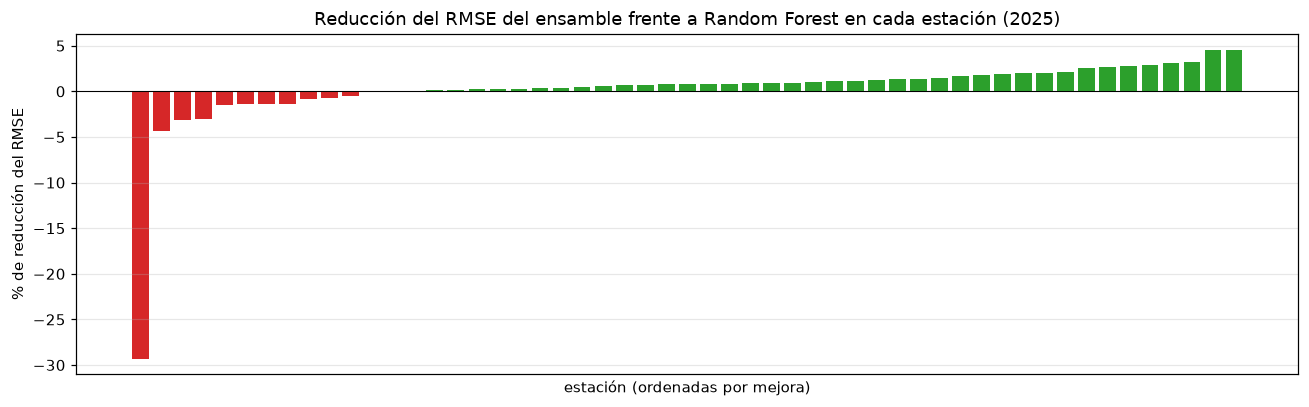

Estaciones donde el ensamble mejora: 41 de 53 | mediana 0.81 % | estaciones sin entrenamiento: 5, mejora media en ellas 0.10 %


In [10]:
d_est = pd.DataFrame({"est": TE.est.to_numpy(), "rf": (y_te - P25["Random Forest"]) ** 2,
                      "en": (y_te - P25[ENSAMBLE]) ** 2}).groupby("est").agg(rf=("rf", "mean"), en=("en", "mean"),
                                                                          filas=("rf", "size"))
d_est["mejora RMSE (%)"] = 100 * (1 - np.sqrt(d_est.en) / np.sqrt(d_est.rf))
d_est = d_est.sort_values("mejora RMSE (%)")
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.bar(range(len(d_est)), d_est["mejora RMSE (%)"], color=np.where(d_est["mejora RMSE (%)"] > 0, "C2", "C3"))
ax.axhline(0, color="k", lw=.7)
ax.set(xlabel="estación (ordenadas por mejora)", ylabel="% de reducción del RMSE",
       title="Reducción del RMSE del ensamble frente a Random Forest en cada estación (2025)")
ax.set_xticks([])
plt.tight_layout()
plt.show()
sin_hist = ~d_est.index.isin(set(TR.est))
print(f"Estaciones donde el ensamble mejora: {(d_est['mejora RMSE (%)'] > 0).sum()} de {len(d_est)} | "
      f"mediana {d_est['mejora RMSE (%)'].median():.2f} % | estaciones sin entrenamiento: {sin_hist.sum()}, "
      f"mejora media en ellas {d_est.loc[sin_hist, 'mejora RMSE (%)'].mean():.2f} %")

El ensamble mejora a Random Forest en `41` de las `53` estaciones, con una mediana de `0.81 %`; en las mejores
la reducción llega al `4.5 %`. En las `5` estaciones que no tenían ningún dato de entrenamiento la mejora es casi
nula (`0.10 %`): ahí PADRE toma las anclas de la vecina y pierde su ventaja, que es conocer el nivel del sitio.

La barra roja grande es Puerto Estrella (La Guajira), donde el ensamble es un `29 %` peor. Su viento medio fue de
`5`–`6 m/s` en 2022, bajó a `3.8 m/s` a finales de 2024 y en noviembre y diciembre de 2025 es de `1.75 m/s`, un
cambio de nivel que sugiere un cambio en el sensor o en su entorno. PADRE toma el nivel de la estación de sus
anclas, que vienen del pasado, y por eso arrastra el nivel antiguo (pronostica en promedio `3.3 m/s`). Es la
debilidad esperable del método: supone que lo propio de cada sitio no cambia. Aun con esta estación, el ensamble
gana en el total; sin ella, la ventaja es mayor (`0.7194` frente a `0.7237`).

### Pronóstico en una estación

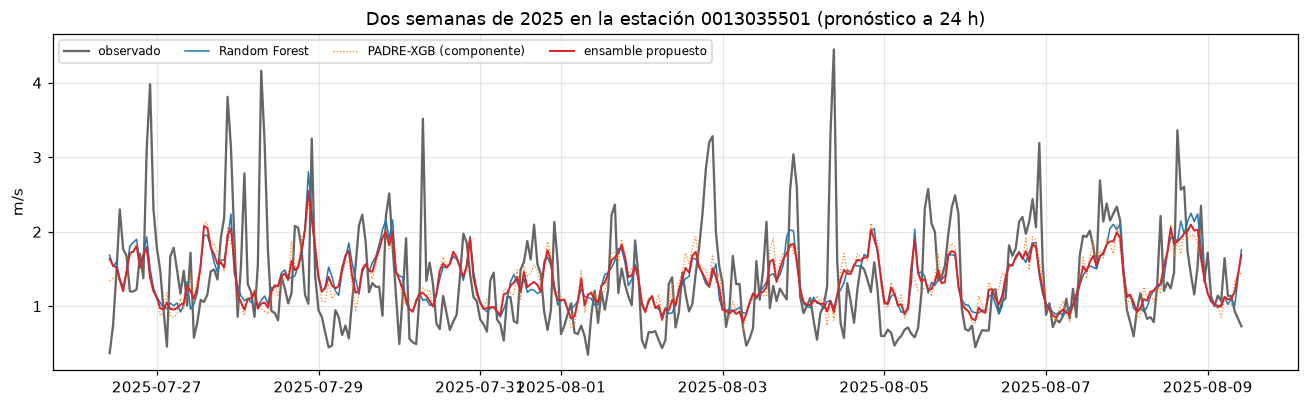

In [11]:
EST = TE.est.value_counts().idxmax()
m_ = (TE.est == EST).to_numpy()
z = pd.DataFrame({"t": TE.t_y[m_].to_numpy(), "y": y_te[m_], "rf": P25["Random Forest"][m_], "en": P25[ENSAMBLE][m_],
                  "pa": P25["PADRE-XGB"][m_]}).sort_values("t").set_index("t")
z = z[z.index >= z.index[len(z) // 2]].iloc[:24 * 14]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(z.index, z.y, color="0.4", label="observado")
ax.plot(z.index, z.rf, color="C0", lw=1, label="Random Forest")
ax.plot(z.index, z.pa, color="C1", lw=.8, ls=":", label="PADRE-XGB (componente)")
ax.plot(z.index, z.en, color="C3", lw=1.3, label="ensamble propuesto")
ax.set(ylabel="m/s", title=f"Dos semanas de 2025 en la estación {EST} (pronóstico a 24 h)")
ax.legend(fontsize=8, ncol=4)
plt.tight_layout()
plt.show()

En la escala horaria el ensamble y Random Forest casi se superponen: una diferencia del `0.5 %` en el RMSE no se
ve a simple vista. PADRE-XGB se separa de ellos en algunos tramos, y el ensamble queda entre ambos; esos
desacuerdos son los que el promedio aprovecha. Ninguno anticipa los picos de una o dos horas, igual que los
modelos del capítulo anterior.

### Residuos

In [12]:
filas = []
for k in [ENSAMBLE, "Random Forest", "XGBoost"]:
    e = y_te - P25[k]
    w_ = ev.prueba_white(e, TE[F].to_numpy(np.float32))
    ind_ = ev.pruebas_independencia(TE.est.to_numpy(), TE.t.to_numpy(), e)
    filas.append({"modelo": k, "media": e.mean(), "p White": w_["p_valor"],
                  "% estaciones BDS p < 0.05": 100 * (ind_.p_BDS < .05).mean(),
                  "% estaciones Ljung-Box p < 0.05": 100 * (ind_.p_LjungBox < .05).mean(),
                  "asimetría": stats.skew(e), "curtosis en exceso": stats.kurtosis(e)})
pd.DataFrame(filas).set_index("modelo").round(4)

,media,p White,% estaciones BDS p < 0.05,% estaciones Ljung-Box p < 0.05,asimetría,curtosis en exceso
modelo,,,,,,
Ensamble PADRE (5),-0.0133,0.0,100.0,100.0,0.8534,3.9555
Random Forest,-0.0113,0.0,100.0,100.0,0.8718,4.0161
XGBoost,0.0069,0.0,100.0,100.0,0.9121,4.0354


Los residuos del ensamble tienen la misma estructura que los de Random Forest y XGBoost: heterocedasticidad (White),
dependencia en todas las estaciones (BDS y Ljung-Box), asimetría positiva (`0.85`) y colas pesadas (curtosis en
exceso cercana a `4`). La asimetría y la curtosis bajan un poco frente a los dos modelos del curso. El sesgo medio
es de `−0.013 m/s`, del mismo orden que el de Random Forest (`−0.011`). El ensamble reduce el error, pero no
cambia su naturaleza: la parte que falta sigue siendo la que no está en los datos.

## 6.6 Auditoría de componentes: quitar y poner PADRE

El ensamble contiene modelos del curso, así que hay que comprobar que la mejora viene del componente nuevo y no
solo de promediar. Para eso comparamos varios promedios de modelos del curso **sin** y **con** los dos PADRE.
Esta auditoría es posterior a la evaluación de 2025: no se usa para elegir nada, solo para explicar el resultado.

In [13]:
def auditoria(y, t, P):
    grupos = {"RF + XGB": ["Random Forest", "XGBoost"], "RF + XGB + SVR": ["Random Forest", "XGBoost", "SVR"],
              "RF + XGB + SVR + KNN": ["Random Forest", "XGBoost", "SVR", "KNN"], "los 7 del curso": list(OPT)}
    filas = []
    for nom, g in grupos.items():
        sin = np.mean([P[m] for m in g], 0)
        con = np.mean([P[m] for m in g] + [P["PADRE-XGB"], P["PADRE-RF"]], 0)
        L = ev.perdida_diaria(t, y, {"sin": sin, "con": con, "RF": P["Random Forest"]})
        dm = ev.diebold_mariano(L.con, L.sin)
        cw_ = ev.clark_west(L.sin, L.con, ev.perdida_diaria(t, sin, {"d": con}).d)
        filas.append({"promedio": nom, "RMSE sin PADRE": rmse(y, sin), "RMSE con PADRE": rmse(y, con),
                      "DM con vs. sin": dm["DM_HLN"], "p DM": dm["p_valor"], "CW": cw_["CW"], "p CW": cw_["p_valor"],
                      "p sin PADRE vs. RF": ev.diebold_mariano(L.sin, L.RF)["p_valor"],
                      "p con PADRE vs. RF": ev.diebold_mariano(L.con, L.RF)["p_valor"]})
    return pd.DataFrame(filas).set_index("promedio")


aud = pd.concat({"2024": auditoria(y24, t24, P24), "2025": auditoria(y_te, TE.t.to_numpy(), P25)})
aud.round(4)

RMSE sin PADRE  RMSE con PADRE  DM con vs. sin  \
     promedio                                                               
2024 RF + XGB                      0.8289          0.8250         -3.6839   
     RF + XGB + SVR                0.8276          0.8216         -4.4009   
     RF + XGB + SVR + KNN          0.8272          0.8197         -5.0096   
     los 7 del curso               0.8295          0.8225         -6.0664   
2025 RF + XGB                      0.7222          0.7212         -1.7085   
     RF + XGB + SVR                0.7221          0.7193         -3.7189   
     RF + XGB + SVR + KNN          0.7188          0.7160         -4.3372   
     los 7 del curso               0.7210          0.7173         -7.5350   

                             p DM       CW  p CW  p sin PADRE vs. RF  \
     promedio                                                          
2024 RF + XGB              0.0003   9.2181   0.0              0.0009   
     RF + XGB + SVR        0.0000   8.5744   0.0              0.0086   
     RF + XGB + SVR + KNN  0.0000   8.3751   0.0              0.0051   
     los 7 del curso       0.0000   8.2062   0.0              0.6395   
2025 RF + XGB              0.0885  12.8013   0.0              0.3211   
     RF + XGB + SVR        0.0002  13.4974   0.0              0.1646   
     RF + XGB + SVR + KNN  0.0000  12.2526   0.0              0.0000   
     los 7 del curso       0.0000  12.4200   0.0              0.1314   

                           p con PADRE vs. RF  
     promedio                                  
2024 RF + XGB                          0.0000  
     RF + XGB + SVR                    0.0000  
     RF + XGB + SVR + KNN              0.0000  
     los 7 del curso                   0.0001  
2025 RF + XGB                          0.0561  
     RF + XGB + SVR                    0.0023  
     RF + XGB + SVR + KNN              0.0000  
     los 7 del curso                   0.0002

Agregar los dos PADRE reduce el RMSE de **todos** los promedios, en 2024 y en 2025. Con Clark-West, la prueba
adecuada porque el promedio con PADRE contiene al promedio sin PADRE, la mejora es significativa en los ocho casos
(`CW` entre `8.2` y `13.5`). Con Diebold-Mariano es significativa en siete de ocho; la excepción es RF + XGB en
2025 (`p = 0.089`).

La comparación clave es la del ensamble: **sin PADRE, el promedio de Random Forest, XGBoost y SVR no se distingue
de Random Forest en 2025 (`p = 0.165`); con PADRE, sí (`p = 0.0023`)**. Lo que convierte un empate en una ventaja
significativa es el componente nuevo.

Un resultado que reportamos por transparencia: el promedio de cuatro modelos del curso (RF, XGB, SVR y KNN), que
no evaluamos antes de 2025, también supera a Random Forest en 2025 (`p < 0.001`) y tiene un RMSE de `0.7188`. Es
decir, promediar modelos del curso puede ayudar por sí solo. Aun en ese caso, agregarle PADRE lo mejora de nuevo
con significancia (`0.7188 → 0.7160`, `DM = −4.34`). No adoptamos ninguno de estos promedios encontrados después de
la prueba: hacerlo sería elegir mirando 2025.

## 6.7 Robustez

### Semillas

PADRE tiene dos fuentes de azar: el sorteo de los pares de entrenamiento y el de las anclas. Repetimos el ensamble
completo con otras cuatro semillas.

In [14]:
pd.read_csv(ENS / "semillas.csv", index_col=0).round(4)

,RMSE ensamble,DM vs RF,p Holm vs RF,p Holm máximo (7 rivales),CW vs RF
semilla,,,,,
42,0.7193,-3.0779,0.0023,0.0023,9.6328
1,0.7193,-3.0040,0.0029,0.0029,8.7440
2,0.7192,-2.9426,0.0035,0.0035,8.9642
3,0.7197,-2.8443,0.0047,0.0047,8.9540
4,0.7194,-3.0401,0.0026,0.0026,8.9534
media,0.7194,-2.9818,0.0032,0.0032,9.0497
desv. est.,0.0002,0.0916,0.0010,0.0010,0.3388


Con las cinco semillas el RMSE de 2025 es `0.7194 ± 0.0002` y el ensamble supera con significancia a los siete
modelos (el mayor p de Holm, siempre frente a Random Forest, está entre `0.0023` y `0.0047`). El resultado no
depende de un sorteo favorable.

### Variante base: PADRE + XGBoost

Antes del ensamble fijamos una versión más simple, con un solo modelo del curso: `w · PADRE-XGB + (1 − w) ·
XGBoost`. Aquí PADRE tuvo su propia búsqueda anidada (espacio de XGBoost más `pares ∈ {2, 4, 8}` y
`anclas ∈ {10, 20, 40}`, `40` configuraciones aleatorias) y el peso `w` se eligió en la validación interna de
cada pliegue.

In [15]:
display(pd.read_csv(RESULTADOS / "padre_anidado.csv", index_col=0).rename(
    columns={"rmse_xgb": "RMSE XGBoost", "rmse_padre": "RMSE PADRE solo", "rmse": "RMSE mezcla",
             "peso_padre": "w elegido", "mejor_rmse_interno": "RMSE interno"}).round(4))
pd.read_csv(RESULTADOS / "padre_comparacion_2025_padre_anidado_pruebas.csv", index_col=0)[
    ["dif. media pérdida", "IC 95 %", "DM-HLN", "p DM (Holm)", "p GW (Holm)"]].round(5)

,RMSE XGBoost,RMSE PADRE solo,RMSE mezcla,w elegido,RMSE interno
pliegue,,,,,
2024-T1,0.9434,1.0077,0.9366,0.15,0.8568
2024-T2,0.9724,0.9823,0.9611,0.25,0.8953
2024-T3,0.9022,0.9057,0.8832,0.35,0.9212
2024-T4,0.7620,0.7906,0.7625,0.60,0.9331
final,0.7268,0.7398,0.7221,0.55,0.8871


,dif. media pérdida,IC 95 %,DM-HLN,p DM (Holm),p GW (Holm)
rival,,,,,
XGBoost,-0.00900,-0.0146 – -0.0036,-4.68780,0.00002,0.00000
Random Forest,-0.00397,-0.0111 – 0.0027,-1.16492,0.24495,0.48460
SVR,-0.01257,-0.0201 – -0.0043,-3.14565,0.00727,0.00001
Ridge,-0.01690,-0.0297 – -0.0048,-2.90290,0.01188,0.00004
Lasso,-0.01690,-0.0297 – -0.0048,-2.90308,0.01188,0.00004
KNN,-0.02295,-0.0336 – -0.0144,-5.05686,0.00000,0.00000
Árbol de decisión,-0.06504,-0.0830 – -0.0512,-11.75592,0.00000,0.00000


La variante base también mejora a XGBoost en los cuatro trimestres de 2024 y en 2025 (`0.7221` frente a
`0.7268`), con `w` entre `0.15` y `0.60`: PADRE solo es peor que XGBoost, pero la mezcla es mejor que ambos, como
predice la descomposición de la sección 6.1. En 2025 supera con significancia a seis de los siete modelos; frente a
Random Forest la diferencia no es significativa (`p = 0.24`). El ensamble agrega a Random Forest, SVR y PADRE-RF, y
con eso pasa de empatar a superar a Random Forest.

## 6.8 Otros candidatos y por qué no se adoptaron

Antes y después de PADRE probamos otras ideas. Cada una tuvo una regla escrita antes de correrla: solo se llevaba a
2025 si en la validación de 2024 superaba a Random Forest con `p < 0.05` (o a los siete, en el caso de PADRE sin
modelos del curso).

In [16]:
dec = {k: json.loads((RESULTADOS / f"{k}/decision.json").read_text(encoding="utf-8"))
       for k in ["merf_anidado", "rotacion_anidado", "padre_solo"]}
cx = pd.read_csv(RESULTADOS / "combinacion_exploracion.csv", index_col=0)
ps = pd.read_csv(RESULTADOS / "padre_solo/2024_pruebas.csv", index_col=0)
pd.DataFrame([
    {"candidato": "Corrección multi-tarea por estación con grafo geográfico (sobre RF + XGB + SVR)",
     "RMSE 2024": cx.loc["Promedio + MT", "RMSE 2024"], "RMSE 2024 RF": 0.8325,
     "resultado": "mejora la base, pero el término del grafo no aporta (igual con λ₂ = 0) y PADRE la supera; descartado"},
    {"candidato": "PADRE-XGB + PADRE-RF, sin modelos del curso",
     "RMSE 2024": dec["padre_solo"]["RMSE 2024"], "RMSE 2024 RF": 0.8325,
     "resultado": f"solo supera con significancia a {int((ps['p (Holm)'] < .05).sum())} de 7 (KNN y árbol); regla no cumplida"},
    {"candidato": "Random Forest de efectos mixtos por estación (MERF)",
     "RMSE 2024": dec["merf_anidado"]["RMSE 2024 MERF"], "RMSE 2024 RF": dec["merf_anidado"]["RMSE 2024 RF"],
     "resultado": f"peor que RF (DM = {dec['merf_anidado']['DM-HLN vs RF']:.2f}); regla no cumplida"},
    {"candidato": "Rotation Forest (rotaciones PCA por grupos de predictoras)",
     "RMSE 2024": dec["rotacion_anidado"]["RMSE 2024 Rotation Forest"], "RMSE 2024 RF": dec["rotacion_anidado"]["RMSE 2024 RF"],
     "resultado": f"empata con RF (p = {dec['rotacion_anidado']['p']:.2f}); regla no cumplida"},
]).set_index("candidato").round(4)

,RMSE 2024,RMSE 2024 RF,resultado
candidato,,,
Corrección multi-tarea por estación con grafo geográfico (sobre RF + XGB + SVR),0.8263,0.8325,"mejora la base, pero el término del grafo no aporta (igual con λ₂ = 0) y PADRE la supera; descartado"
"PADRE-XGB + PADRE-RF, sin modelos del curso",0.8567,0.8325,solo supera con significancia a 2 de 7 (KNN y árbol); regla no cumplida
Random Forest de efectos mixtos por estación (MERF),0.8881,0.8325,peor que RF (DM = 3.80); regla no cumplida
Rotation Forest (rotaciones PCA por grupos de predictoras),0.8339,0.8325,empata con RF (p = 0.92); regla no cumplida


Ningún modelo individual superó a Random Forest: la corrección multi-tarea mejora el promedio pero su grafo no
aporta, MERF falla por la misma estación con `11` filas de entrenamiento que obligó a crear la regla de la vecina
en PADRE, Rotation Forest queda prácticamente igual a Random Forest (`0.8339` frente a `0.8325`) y PADRE sin
modelos del curso es peor que XGBoost y Random Forest. El patrón es coherente con el límite de información del
capítulo anterior: cambiar el algoritmo no basta; lo que funcionó fue **combinar pronósticos que se equivocan
distinto**, y PADRE es el componente que aporta ese error distinto.

### Costo computacional

Entrenar los dos PADRE de un pliegue toma entre `8` y `13 s` con motor XGBoost (GPU) y entre `149` y `301 s` con
motor Random Forest (16 hilos), porque el conjunto de pares tiene cuatro veces más filas. El pronóstico promedia
`20` anclas, así que predecir cuesta unas `20` veces más que con el motor solo (unos `19 s` para las `213 972`
filas de 2025 con PADRE-XGB). Los tres modelos del curso ya estaban entrenados, de modo que el costo adicional del
ensamble es el de los dos PADRE.

## 6.9 Conclusiones

1. Proponemos un ensamble que promedia, sin pesos ajustados, Random Forest, XGBoost, SVR y dos versiones de la
   regresión por diferencias de pares por estación. La versión por estación es propia de este trabajo y no
   encontramos aplicaciones de PADRE al pronóstico de viento en Scopus, Web of Science ni entre los artículos que
   citan el método.
2. En la prueba de 2025, evaluada una sola vez, el ensamble obtiene `RMSE = 0.7193 m/s` y supera con diferencia
   significativa a cada uno de los siete modelos del curso (Diebold-Mariano con Holm; frente a Random Forest
   `p = 0.0023`). Clark-West, SPA y el Model Confidence Set apuntan en la misma dirección, y el resultado se
   repite con cinco semillas y en la validación de 2024.
3. La auditoría de componentes muestra que la ventaja viene de PADRE: sin él, el promedio de los tres modelos del
   curso empata con Random Forest; con él, lo supera. La descomposición de ambigüedad explica por qué: PADRE
   aumenta el desacuerdo entre los componentes sin aumentar mucho su error medio.
4. La mejora es pequeña en magnitud (`0.5 %` del RMSE frente a Random Forest). Todos los modelos usan solo las
   mediciones de las estaciones; el siguiente paso con más potencial es agregar información sobre el futuro, como
   pronósticos numéricos del tiempo (GFS) o variables de reanálisis (ERA5) del momento de emisión.

**Limitaciones.** La significancia se obtiene sobre un solo año de prueba; con otro año la ventaja podría ser
menor. PADRE supone que el nivel propio de cada estación no cambia: cuando cambia, como en Puerto Estrella, las
anclas arrastran el nivel antiguo; usar solo anclas recientes sería la corrección natural, aunque en 2024 las
anclas de los últimos `90` días dieron peor resultado. Las estaciones con poca historia dependen de la regla de la
vecina, que es una aproximación. PADRE
multiplica el costo de predicción por el número de anclas. Los promedios de modelos del curso que encontramos
después de la prueba muestran que parte de la ganancia de combinar no es exclusiva de PADRE, aunque PADRE la
aumenta en todos los casos.

In [17]:
import platform
import sklearn
import xgboost

print(f"Python {platform.python_version()} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | xgboost {xgboost.__version__}")

Python 3.11.16 | numpy 2.4.6 | pandas 3.0.6 | scikit-learn 1.9.1 | xgboost 3.2.0
